In [1]:
!git clone https://github.com/ycwsorry/maize-disease-detection-dataset.git /kaggle/working/maize-disease-detection

Cloning into '/kaggle/working/maize-disease-detection'...
remote: Enumerating objects: 18853, done.
remote: Total 18853 (delta 0), reused 0 (delta 0), pack-reused 18853 (from 3)
Receiving objects: 100% (18853/18853), 879.23 MiB | 47.89 MiB/s, done.
Resolving deltas: 100% (305/305), done.
Updating files: 100% (30252/30252), done.


In [2]:
from pathlib import Path

REPO = Path(
    "/kaggle/working/maize-disease-detection"
)

print("Repository exists:", REPO.exists())
print("\nFiles/Folders:")

for p in sorted(REPO.iterdir()):
    print(p.name)

Repository exists: True

Files/Folders:
.git
README.md
class_instance_statistics.csv
corn_disease_only.yaml
data_check_report
data_sources.csv
dataset_statistics.csv
images
labels
splits


In [3]:
# for folder in ["images", "labels", "splits"]:
#     path = REPO / folder

#     print(f"\n===== {folder} =====")

#     for p in sorted(path.rglob("*")):
#         if p.is_file():
#             print(p.relative_to(REPO))

In [4]:
from pathlib import Path

for folder in ["images", "labels", "splits"]:
    path = REPO / folder

    print(f"\n===== {folder} =====")

    for item in sorted(path.iterdir()):
        if item.is_dir():
            files = list(item.rglob("*"))
            file_count = sum(p.is_file() for p in files)
            print(f"{item.name}/  →  {file_count} files")

        else:
            print(item.name)


===== images =====
test/  →  1506 files
train/  →  10609 files
val/  →  3004 files

===== labels =====
test/  →  1506 files
train/  →  10609 files
val/  →  3004 files

===== splits =====
test_images.txt
train_images.txt
val_images.txt


In [5]:
yaml_path = REPO / "corn_disease_only.yaml"

print(yaml_path.read_text())

path: ../datasets/corn-dis
train: train/images
val: val/images
test: test/images
nc: 8
names:
- Blight
- brown_spot
- corn_rust
- corn_smut
- downy_mildew
- grey_leaf_spot
- healthy
- maize-streak-disease



In [6]:
yaml_content = f"""
path: {REPO}
train: images/train
val: images/val
test: images/test

nc: 8
names:
- Blight
- brown_spot
- corn_rust
- corn_smut
- downy_mildew
- grey_leaf_spot
- healthy
- maize-streak-disease
"""

YAML_PATH = REPO / "kaggle_data.yaml"
YAML_PATH.write_text(yaml_content)

print(YAML_PATH.read_text())


path: /kaggle/working/maize-disease-detection
train: images/train
val: images/val
test: images/test

nc: 8
names:
- Blight
- brown_spot
- corn_rust
- corn_smut
- downy_mildew
- grey_leaf_spot
- healthy
- maize-streak-disease



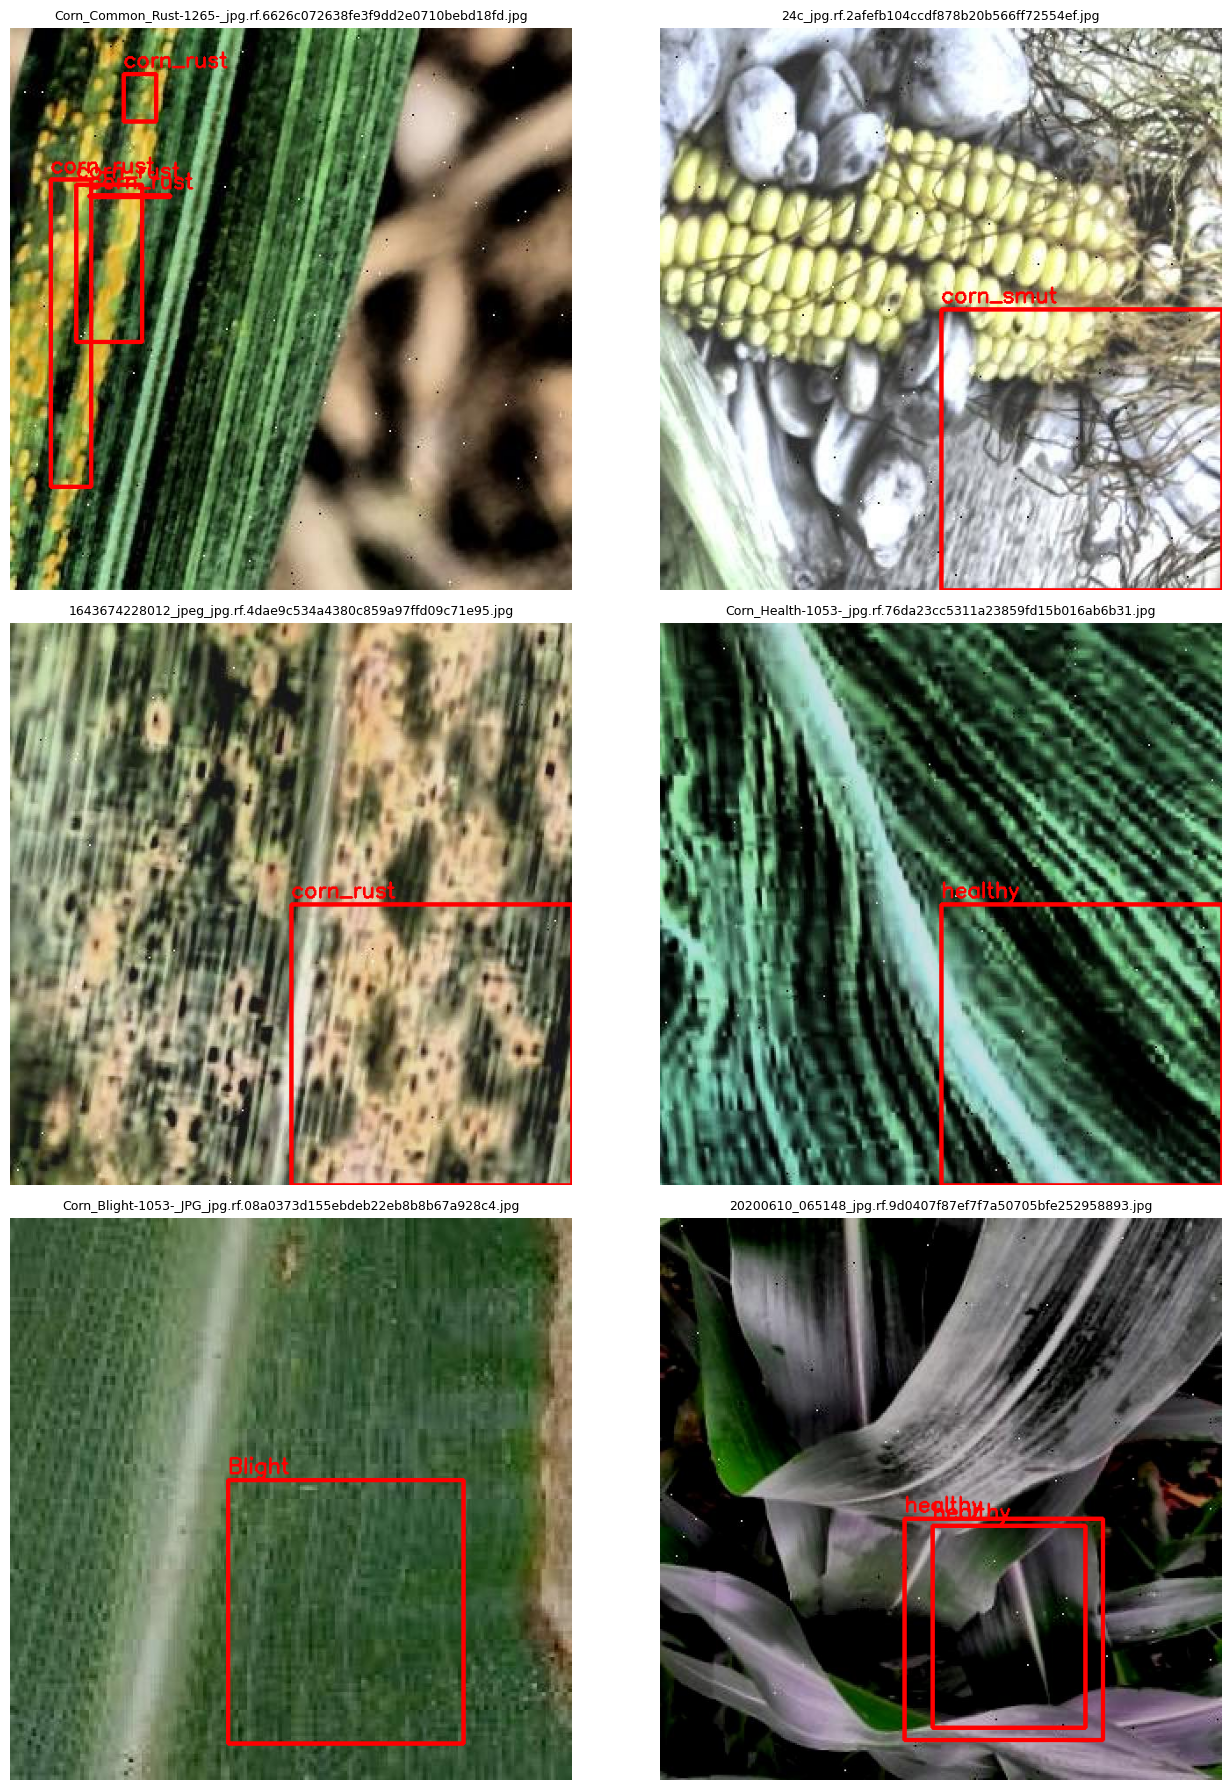

In [7]:
import cv2
import random
import matplotlib.pyplot as plt

CLASS_NAMES = ["Blight","brown_spot","corn_rust","corn_smut","downy_mildew","grey_leaf_spot","healthy","maize-streak-disease"]
IMG_DIR = REPO / "images/train"
LABEL_DIR = REPO / "labels/train"

images = list(IMG_DIR.glob("*.jpg"))
selected = random.sample(images, 6)
fig, axes = plt.subplots(3, 2, figsize=(14, 18))

for ax, img_path in zip(axes.flat, selected):
    img = cv2.imread(str(img_path))
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    h, w = img.shape[:2]
    label_path = LABEL_DIR / f"{img_path.stem}.txt"

    if label_path.exists():
        with open(label_path) as f:
            for line in f:
                v = line.strip().split()
                cls = int(v[0])
                coords = list(map(float, v[1:]))
                xs = [coords[i]*w for i in range(0, len(coords), 2)]
                ys = [coords[i]*h for i in range(1, len(coords), 2)]
                x1, x2 = int(min(xs)), int(max(xs))
                y1, y2 = int(min(ys)), int(max(ys))
                cv2.rectangle(img, (x1,y1), (x2,y2), (255,0,0), 3)
                cv2.putText(img, CLASS_NAMES[cls], (x1,y1-8), cv2.FONT_HERSHEY_SIMPLEX, 0.8, (255,0,0), 2)

    ax.imshow(img)
    ax.set_title(img_path.name, fontsize=9)
    ax.axis("off")

plt.tight_layout()
plt.show()


IMAGE: 10c_jpg.rf.70794152b24f968b2400b4ec8609bd6d.jpg
LABEL: /kaggle/working/maize-disease-detection/labels/train/10c_jpg.rf.70794152b24f968b2400b4ec8609bd6d.txt
LABEL CONTENT:
4 0.773438 0.126562 0.453125 0.253125
4 0.117188 0.356250 0.234375 0.712500
4 0.768750 0.695312 0.462500 0.609375

IMAGE: 20200610_063709_jpg.rf.2fd1da0286955f854bf31c9f1226b7a4.jpg
LABEL: /kaggle/working/maize-disease-detection/labels/train/20200610_063709_jpg.rf.2fd1da0286955f854bf31c9f1226b7a4.txt
LABEL CONTENT:
6 0.435937 0.500000 0.578125 1.000000

IMAGE: IMG_1058_jpg.rf.9dfb3aafd25f3bfc382cd56aca26bf1c.jpg
LABEL: /kaggle/working/maize-disease-detection/labels/train/IMG_1058_jpg.rf.9dfb3aafd25f3bfc382cd56aca26bf1c.txt
LABEL CONTENT:
0 0.500000 0.845313 1.000000 0.309375

IMAGE: 43_jpg.rf.99a58aaab53d9900324df94d75b24b3e.jpg
LABEL: /kaggle/working/maize-disease-detection/labels/train/43_jpg.rf.99a58aaab53d9900324df94d75b24b3e.txt
LABEL CONTENT:
2 0.500000 0.589063 1.000000 0.803125

IMAGE: Corn-gray-leaf-s

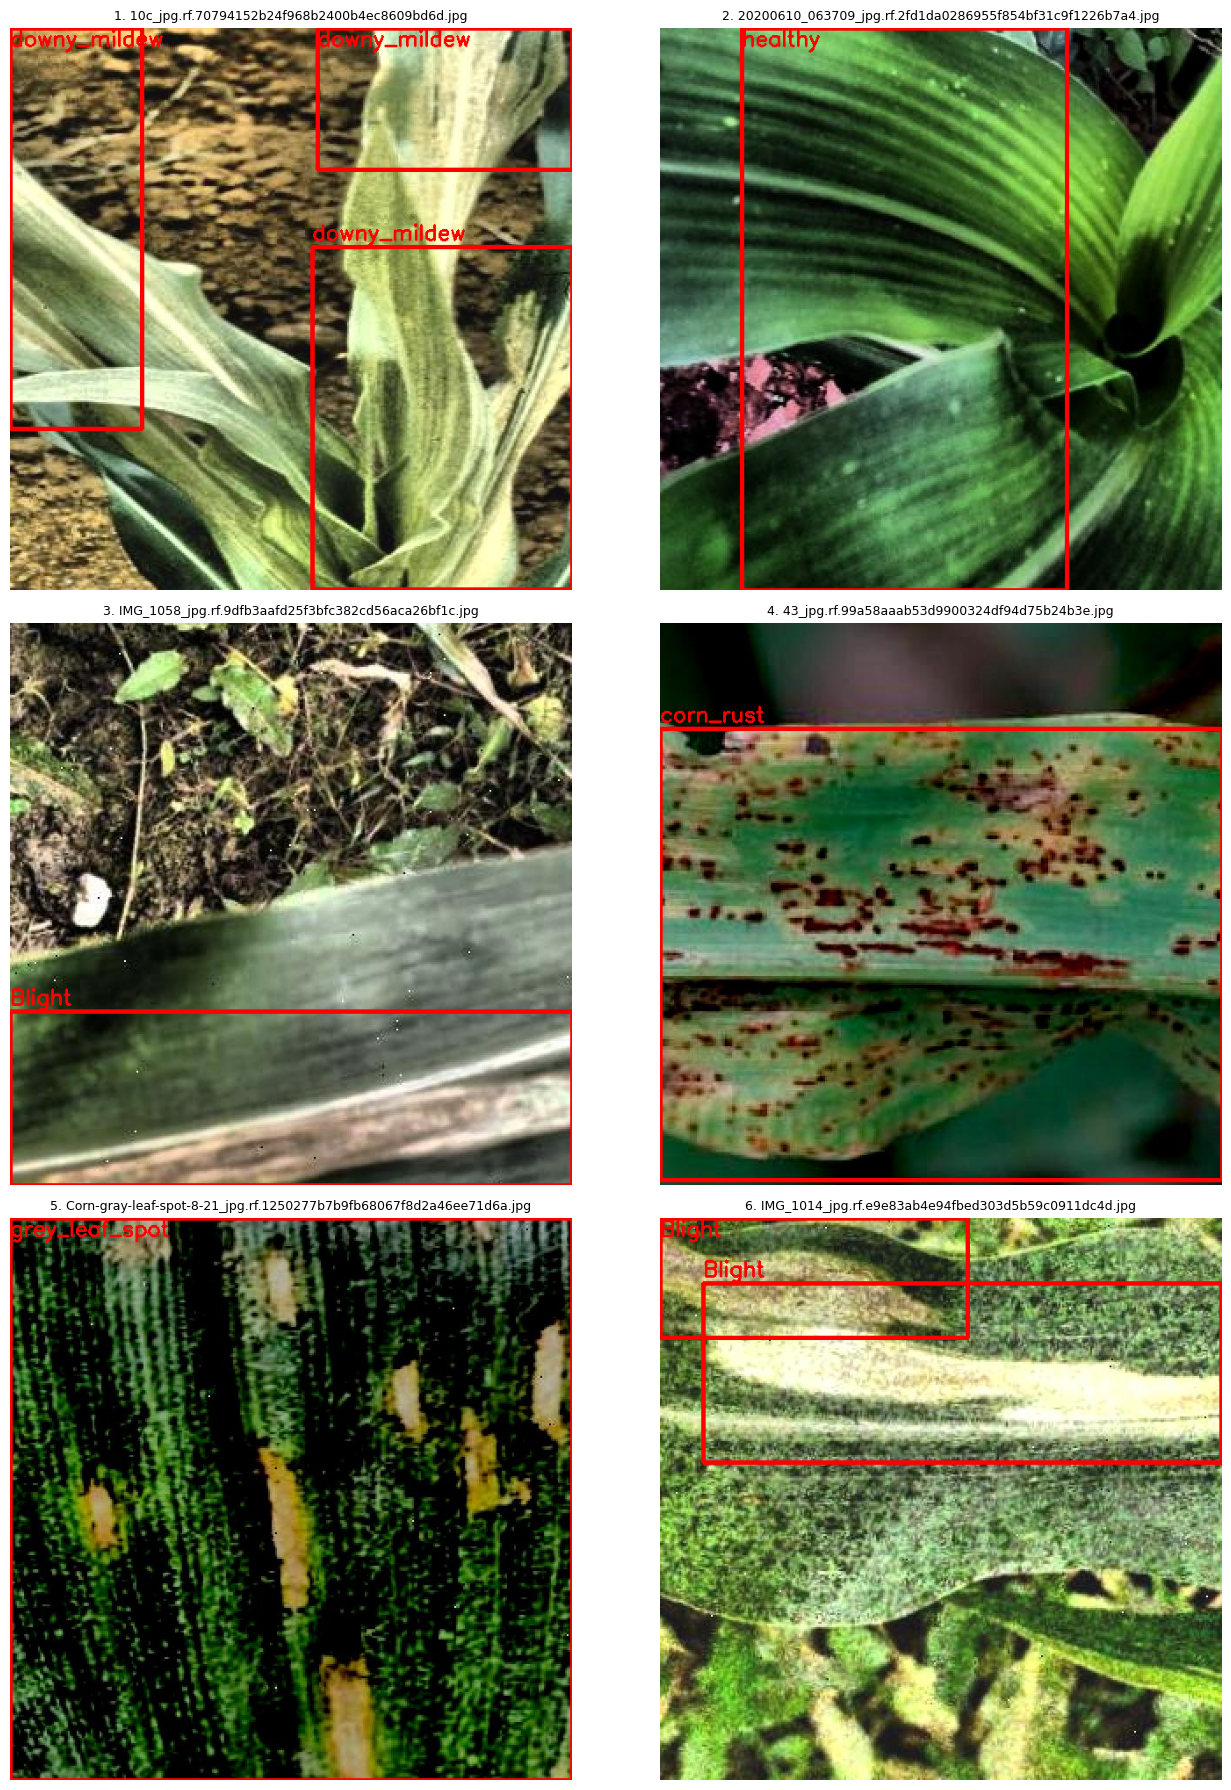

In [8]:
import cv2
import random
import matplotlib.pyplot as plt

CLASS_NAMES = ["Blight","brown_spot","corn_rust","corn_smut","downy_mildew","grey_leaf_spot","healthy","maize-streak-disease"]
IMG_DIR = REPO / "images/train"
LABEL_DIR = REPO / "labels/train"

images = list(IMG_DIR.glob("*"))
selected = random.sample(images, 6)
fig, axes = plt.subplots(3, 2, figsize=(14, 18))

for i, (ax, img_path) in enumerate(zip(axes.flat, selected)):
    img = cv2.imread(str(img_path))
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    h, w = img.shape[:2]
    label_path = LABEL_DIR / f"{img_path.stem}.txt"

    print(f"\n{'='*80}")
    print(f"IMAGE: {img_path.name}")
    print(f"LABEL: {label_path}")
    print("LABEL CONTENT:")

    if label_path.exists():
        with open(label_path) as f:
            lines = [line.strip() for line in f if line.strip()]

        for line in lines:
            print(line)

        for line in lines:
            v = line.split()
            if len(v) != 5:
                continue
            cls, xc, yc, bw, bh = map(float, v)
            xc, yc, bw, bh = xc*w, yc*h, bw*w, bh*h
            x1, y1 = int(xc-bw/2), int(yc-bh/2)
            x2, y2 = int(xc+bw/2), int(yc+bh/2)
            cv2.rectangle(img, (x1,y1), (x2,y2), (255,0,0), 3)
            cv2.putText(img, CLASS_NAMES[int(cls)], (x1,max(y1-8,20)), cv2.FONT_HERSHEY_SIMPLEX, 0.8, (255,0,0), 2)
    else:
        print("LABEL FILE NOT FOUND")

    ax.imshow(img)
    ax.set_title(f"{i+1}. {img_path.name}", fontsize=9)
    ax.axis("off")

plt.tight_layout()
plt.show()

In [9]:
from collections import Counter

label_counts = Counter()
label_files = list((REPO / "labels/train").glob("*.txt"))

for label_file in label_files:
    with open(label_file) as f:
        for line in f:
            v = line.strip().split()
            if len(v) == 5:
                label_counts[int(v[0])] += 1

for i, name in enumerate(CLASS_NAMES):
    print(f"{i}: {name:<22} {label_counts[i]}")

0: Blight                 2724
1: brown_spot             2224
2: corn_rust              3510
3: corn_smut              2853
4: downy_mildew           2470
5: grey_leaf_spot         2727
6: healthy                3320
7: maize-streak-disease   558


In [10]:
# Count class instances in Train, Validation, and Test sets

from collections import Counter

for split in ["train","val","test"]:
    counts = Counter()
    label_files = list((REPO / "labels" / split).glob("*.txt"))
    for label_file in label_files:
        with open(label_file) as f:
            for line in f:
                v = line.strip().split()
                if len(v) == 5:
                    counts[int(v[0])] += 1
    print(f"\n===== {split.upper()} =====")
    for i, name in enumerate(CLASS_NAMES):
        print(f"{i}: {name:<22} {counts[i]}")


===== TRAIN =====
0: Blight                 2724
1: brown_spot             2224
2: corn_rust              3510
3: corn_smut              2853
4: downy_mildew           2470
5: grey_leaf_spot         2727
6: healthy                3320
7: maize-streak-disease   558

===== VAL =====
0: Blight                 808
1: brown_spot             654
2: corn_rust              1056
3: corn_smut              802
4: downy_mildew           731
5: grey_leaf_spot         767
6: healthy                1063
7: maize-streak-disease   152

===== TEST =====
0: Blight                 428
1: brown_spot             347
2: corn_rust              503
3: corn_smut              395
4: downy_mildew           330
5: grey_leaf_spot         430
6: healthy                438
7: maize-streak-disease   76


In [11]:
# Install the Ultralytics package required for YOLO training

!pip install -q ultralytics

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 47.0/47.0 kB 1.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 31.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 97.6/97.6 kB 3.7 MB/s eta 0:00:00


In [12]:
# Load the YOLO11n model for the baseline experiment

from ultralytics import YOLO

model = YOLO("yolo11n.pt")
print("YOLO11n loaded successfully.")

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
YOLO11n loaded successfully.


In [13]:
# Train the YOLO11n baseline model for the final experiment

baseline_results = model.train(
    data=str(YAML_PATH),
    imgsz=640,
    epochs=200,
    batch=16,
    device=0,
    workers=2,
    project="/kaggle/working/maize_yolo_runs",
    name="yolo11n_baseline_final",
    exist_ok=True,
    plots=True,
    verbose=True
)

Ultralytics 8.4.183 🚀 Python-3.12.13 torch-2.10.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/kaggle/working/maize-disease-detection/kaggle_data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=200, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo11n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=yolo11n_baseline_final, nbs=64, 

/usr/local/lib/python3.12/dist-packages/ray/train/_internal/session.py:676: UserWarning: `get_trial_id` is meant to only be called inside a function that is executed by a Tuner or Trainer. Returning `None`.
  warnings.warn(


      2/200      2.75G     0.9275      1.747      1.496          3        640: 100% ━━━━━━━━━━━━ 664/664 7.4it/s 1:30
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 94/94 6.4it/s 14.7s
                   all       3004       6033      0.458      0.283      0.291      0.195

      Epoch    GPU_mem   box_loss   cls_loss   dfl_loss  Instances       Size
      3/200      2.75G     0.9856      1.897      1.543          1        640: 100% ━━━━━━━━━━━━ 664/664 7.6it/s 1:27
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 94/94 6.5it/s 14.5s
                   all       3004       6033       0.33      0.337      0.283      0.169

      Epoch    GPU_mem   box_loss   cls_loss   dfl_loss  Instances       Size
      4/200      2.75G     0.9836      1.888      1.548          3        640: 100% ━━━━━━━━━━━━ 664/664 7.7it/s 1:26
                 Class     Images  Instances      Box(

In [14]:
# Evaluate and save the final YOLO11n baseline test results

best_baseline = YOLO(
    "/kaggle/working/maize_yolo_runs/yolo11n_baseline_final/weights/best.pt"
)

test_results = best_baseline.val(
    data=str(YAML_PATH),
    imgsz=640,
    batch=16,
    device=0,
    split="test",
    project="/kaggle/working/maize_yolo_runs",
    name="yolo11n_baseline_test",
    plots=True,
    verbose=True
)

Ultralytics 8.4.183 🚀 Python-3.12.13 torch-2.10.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
YOLO11n summary (fused): 101 layers, 2,598,752 parameters, 0 gradients, 6.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1823.0±486.4 MB/s, size: 64.2 KB)
val: Scanning /kaggle/working/maize-disease-detection/labels/test... 1506 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 1506/1506 1.3Kit/s 1.2s
val: New cache created: /kaggle/working/maize-disease-detection/labels/test.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 95/95 7.1it/s 13.3s
                   all       1506       2947       0.87      0.838      0.906      0.737
                Blight        205        428      0.914       0.92      0.944      0.746
            brown_spot        146        347      0.831      0.853       0.92      0.633
             corn_rust        238        503      0.859      0.679      0.818       0.62
             corn_smut        239